# Actividad — Construir un pipeline de preprocesamiento
**Aprendizaje Supervisado · Unidad 2 · Preprocesamiento de datos**

**Qué haremos.** En la presentación vimos las piezas del preprocesamiento. Hoy las usarás sobre la versión original de
*California Housing* (con valores faltantes y una variable categórica) y, sobre todo, **medirás** el efecto de cada decisión:
¿qué imputación conviene? ¿importa cómo codifico? ¿qué pasa si escalo mal o si hay fuga de datos?

| Parte | Pregunta que responde | Tema de la presentación |
|---|---|---|
| 1 | ¿Cuántos datos faltan y se parecen las filas con y sin faltante? | A1–A3 |
| 2 | ¿Cómo divido sin distorsionar las proporciones? | D1–D3 |
| 3 | ¿Qué estrategia de imputación recupera mejor los valores ocultos? | A4–A9 |
| 4 | ¿Entero u *one-hot*? ¿Y si el orden sí importa? | B1–B5 |
| 5 | ¿Qué escalador conviene y para qué modelos? | C1–C6 |
| 6 | ¿Cómo se ve (y se evita) una fuga de datos? | D5–D7 |
| 7 | ¿Cómo empaqueto todo con `Pipeline` y `ColumnTransformer`? | E1–E5 |
| 8 | Tabla comparativa y resumen | Receta de siete pasos |

**Tiempo estimado:** 60–75 minutos de trabajo individual.

**Entregable:** este notebook ejecutado (con tus respuestas en las celdas ✏️) y el archivo `entregable_unidad2.csv`
con la tabla *estrategia · RMSE de validación · comentario* de la Parte 8.

**Cómo trabajar.** Ejecuta las celdas en orden. Donde dice ✏️ hay una línea de código por completar o una pregunta;
escribe tus respuestas en la celda de texto que sigue a la pregunta, bajo «**Respuesta:**».
Todas las cifras de error están en **miles de USD** (valor mediano de la vivienda ÷ 1000).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.experimental import enable_iterative_imputer  # noqa: F401  (activa IterativeImputer)
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder, OrdinalEncoder
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import mean_squared_error, r2_score

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 140)

## Parte 0 — Los datos

Usamos la versión del libro de A. Géron (*Hands-On Machine Learning*): $n=20\,640$ distritos de California, con
`total_bedrooms` incompleta y una variable categórica, `ocean_proximity`. El archivo se descarga de GitHub la primera vez
(se necesita conexión a internet).

In [2]:
URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
try:
    df = pd.read_csv(URL)
except Exception:
    df = pd.read_csv("housing.csv")      # plan B: si descargaste el archivo y lo dejaste junto al notebook

NUM = ["longitude", "latitude", "housing_median_age", "total_rooms",
       "total_bedrooms", "population", "households", "median_income"]
CAT = ["ocean_proximity"]
OBJ = "median_house_value"
cv = KFold(5, shuffle=True, random_state=0)      # validación cruzada de 5 particiones, siempre la misma

print(df.shape)
df.head()

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## Parte 1 — Cuantificar los valores faltantes  *(presentación A1–A3)*

Antes de imputar o borrar hay que saber **cuántos** faltan, **dónde**, y si las filas incompletas se parecen a las completas.

In [8]:
n_falt = df.isna().sum()      # ✏️ número de NaN por columna        (pista: df.isna().sum())
pct_falt = 100 * df.isna().mean()    # ✏️ porcentaje de filas con NaN       (pista: 100 * df.isna().mean())
tabla_falt = pd.DataFrame({"faltantes": n_falt, "%": pct_falt.round(2)})
print(tabla_falt[tabla_falt["faltantes"] > 0])
print("Filas completas:", len(df.dropna()), "de", len(df))

                faltantes    %
total_bedrooms        207  1.0
Filas completas: 20433 de 20640


In [9]:
# ¿Se parecen los distritos con y sin dato en total_bedrooms?
falta = df["total_bedrooms"].isna().map({True: "sin dato", False: "con dato"})
cols = ["median_income", "median_house_value", "housing_median_age", "population"]
df.groupby(falta)[cols].mean().round(2)

,median_income,median_house_value,housing_median_age,population
total_bedrooms,,,,
con dato,3.87,206864.41,28.63,1424.95
sin dato,3.82,206007.28,29.27,1477.77


In [10]:
# ¿Hay faltantes "disfrazados"? Revisa ceros y valores imposibles en las columnas numéricas
print((df[NUM] == 0).sum().to_string())
print()
print(df[NUM].describe().loc[["min", "max"]].T)

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0

                         min         max
longitude          -124.3500   -114.3100
latitude             32.5400     41.9500
housing_median_age    1.0000     52.0000
total_rooms           2.0000  39320.0000
total_bedrooms        1.0000   6445.0000
population            3.0000  35682.0000
households            1.0000   6082.0000
median_income         0.4999     15.0001


✏️ **Pregunta 1.1.** Con base en las dos tablas anteriores, ¿qué mecanismo (MCAR, MAR o MNAR) te parece más plausible para `total_bedrooms`?
¿Qué **no** puedes concluir solo con esta comparación? ¿Encontraste faltantes disfrazados?

**Respuesta:**

> El mecanismo más plausible para total_bedrooms sería MCAR, ya que los faltantes no parecen tener relación con las otras variables y parecen ser completamente aleatorios.
>
> No podemos descartar MNAR: la falta de dato podría depender del propio valor de total_bedrooms (por ejemplo, que falte más en distritos con muchas recámaras), y eso no se ve en la tabla porque justo ese valor es el que falta. Además, solo comparamos medias de cuatro variables, así que esto apoya MCAR pero no lo demuestra.
>
> No se encontraron faltantes disfrazados pero si podemos encontrar topes para housing_median_age en 52 y para median_income en 15.0001

## Parte 2 — Dividir **primero**, de forma estratificada  *(presentación D1–D3)*

Regla de la receta: lo primero es separar el conjunto de prueba. Como el ingreso mediano es la variable que más
explica el precio, queremos que la **distribución del ingreso** sea la misma en entrenamiento y en prueba.
Creamos una variable auxiliar `income_cat` (5 categorías de ingreso) solo para **estratificar**.

In [15]:
df["income_cat"] = pd.cut(df["median_income"], bins=[0, 1.5, 3.0, 4.5, 6.0, np.inf], labels=[1, 2, 3, 4, 5])

train, test = train_test_split(df, test_size=0.2, random_state=42, stratify=df["income_cat"])    # ✏️ añade stratify=df["income_cat"]

prop = pd.DataFrame({
    "total": df["income_cat"].value_counts(normalize=True),
    "entrenamiento": train["income_cat"].value_counts(normalize=True),
    "prueba": test["income_cat"].value_counts(normalize=True),
}).sort_index().mul(100).round(1)
print(prop)
print("\nTamaños:", len(train), "entrenamiento |", len(test), "prueba")

            total  entrenamiento  prueba
income_cat                              
1             4.0            4.0     4.0
2            31.9           31.9    31.9
3            35.1           35.1    35.1
4            17.6           17.6    17.6
5            11.4           11.4    11.4

Tamaños: 16512 entrenamiento | 4128 prueba


In [23]:
# Separamos atributos y objetivo (en miles de USD) y quitamos la variable auxiliar
X_train, y_train = train.drop(columns=[OBJ, "income_cat"]), train[OBJ] / 1000
X_test,  y_test  = test.drop(columns=[OBJ, "income_cat"]),  test[OBJ] / 1000
# A partir de aquí, el conjunto de prueba NO se toca hasta el final de la Parte 7/8.
X_train.shape, X_test.shape


((16512, 9), (4128, 9))

✏️ **Pregunta 2.1.** Compara las columnas *total*, *entrenamiento* y *prueba* de la tabla de proporciones.
¿Por qué estratificamos por el ingreso y no por, por ejemplo, `population`? ¿Qué podría pasar con una división aleatoria simple?

**Respuesta:**

> Estratificamos por el ingreso porque es la variable que más explica el precio; population tiene poca relación con él, así que equilibrarla no ayudaría a que la evaluación sea justa. Con una división aleatoria simple, la distribución del ingreso podría quedar distinta entre entrenamiento y prueba (por ejemplo, pocos distritos de ingreso alto en el test), y el error medido en prueba no representaría bien el desempeño real del modelo. Al estratificar, las proporciones de cada income_cat quedan prácticamente iguales en total, entrenamiento y prueba, como se ve en la tabla.

## Parte 3 — ¿Qué imputación recupera mejor los valores? *(presentación A4–A9)*

Para comparar estrategias necesitamos conocer la **verdad**. Tomamos las filas de entrenamiento donde `total_bedrooms` sí
existe, **ocultamos el 20 %** al azar, imputamos y medimos el error contra el valor real.

In [24]:
base = X_train[NUM].dropna(subset=["total_bedrooms"]).reset_index(drop=True)
rng = np.random.default_rng(5)
oculto = rng.random(len(base)) < 0.20                       # True = valor que ocultamos
verdad = base.loc[oculto, "total_bedrooms"].values
X_mask = base.copy()
X_mask.loc[oculto, "total_bedrooms"] = np.nan
j = NUM.index("total_bedrooms")
print(f"Ocultamos {oculto.sum()} de {len(base)} valores")

imputaciones = {}
imputaciones["media"] = SimpleImputer(strategy="mean").fit_transform(X_mask)[oculto, j]      # ✏️ SimpleImputer(strategy=...).fit_transform(X_mask)[oculto, j]
imputaciones["mediana"] = SimpleImputer(strategy="median").fit_transform(X_mask)[oculto, j]    # ✏️ igual, con la mediana

# KNN usa distancias: lo probamos sin escalar y con las variables estandarizadas
imputaciones["KNN (sin escalar)"] = KNNImputer(n_neighbors=5).fit_transform(X_mask)[oculto, j]
esc = StandardScaler().fit(X_mask)
X_knn = KNNImputer(n_neighbors=5).fit_transform(esc.transform(X_mask))
imputaciones["KNN (escalado)"] = esc.inverse_transform(X_knn)[oculto, j]
# Imputación iterativa (tipo MICE)
imputaciones["Iterativa (MICE)"] = IterativeImputer(max_iter=10, random_state=0).fit_transform(X_mask)[oculto, j]

Ocultamos 3313 de 16354 valores


                         RMSE  desv. est.  corr. con households
método                                                         
verdad (sin ocultar)    0.000     412.666                 0.980
media                 397.445     371.883                 0.883
mediana               407.344     374.154                 0.879
KNN (sin escalar)      74.269     409.478                 0.980
KNN (escalado)         64.317     408.732                 0.980
Iterativa (MICE)       67.284     411.746                 0.982


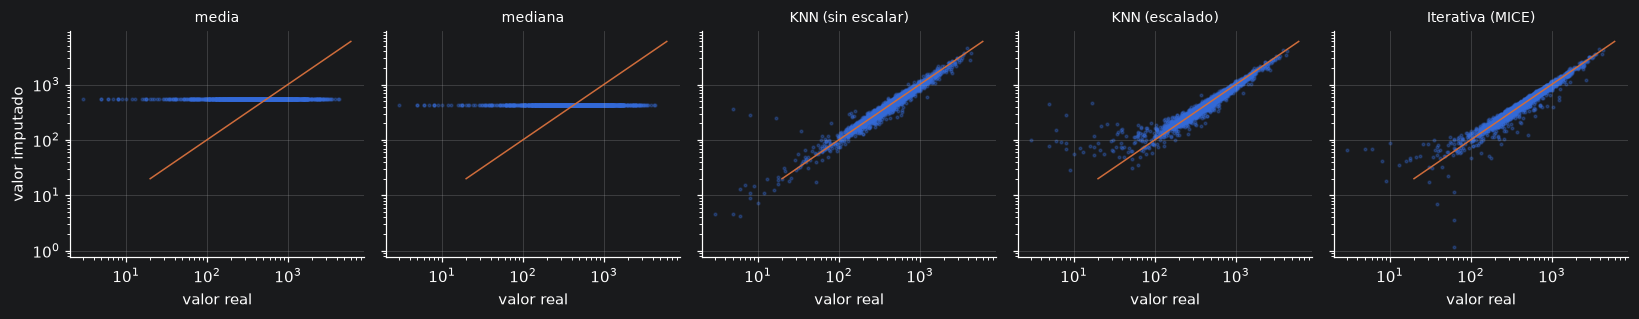

In [25]:
filas = [{"método": "verdad (sin ocultar)", "RMSE": 0.0,
          "desv. est.": base["total_bedrooms"].std(), "corr. con households": base["total_bedrooms"].corr(base["households"])}]
for nombre, vals in imputaciones.items():
    col = base["total_bedrooms"].copy()
    col[oculto] = vals                                      # columna completa tras imputar
    filas.append({"método": nombre,
                  "RMSE": float(np.sqrt(np.mean((vals - verdad) ** 2))),
                  "desv. est.": col.std(),
                  "corr. con households": col.corr(base["households"])})
tabla_imp = pd.DataFrame(filas).set_index("método").round(3)
print(tabla_imp)

fig, ax = plt.subplots(1, 5, figsize=(15, 3), sharex=True, sharey=True)
for a, (nombre, vals) in zip(ax, imputaciones.items()):
    a.scatter(verdad, vals, s=3, alpha=0.3)
    a.plot([20, 6000], [20, 6000], color="C1", lw=1)
    a.set_xscale("log"); a.set_yscale("log"); a.set_title(nombre, fontsize=9); a.set_xlabel("valor real")
ax[0].set_ylabel("valor imputado")
plt.tight_layout(); plt.show()

y✏️ **Pregunta 3.1.** (a) Para media y mediana, ¿por qué el RMSE es tan parecido a la desviación estándar de la variable
y qué se ve en las gráficas? (b) ¿Qué le pasa a la desviación estándar y a la correlación con `households` al imputar con la media?
(c) ¿Qué cambia entre *KNN sin escalar* y *KNN escalado*, y por qué?

**Respuesta:**

> a) Para la media y la mediana rellenamos los faltantes con un mismo valor, por lo que en la gráfica vemos una linea horizontal de los puntos. El RMSE es tan parecido a la desviación estandar porque el error de cada valor es su distancia a la media, que es exactamente lo que mide la desviación estándar.

> b) La desviación estándar y la correlación con households disminuye. Esto porque al ponerle el mismo valor al 20% de los datos, los datos quedan más amontonados justo en el centro de la distribución. Con respecto a la correlación, al darle un mismo valor a los datos, por más diferentes que sea households, esa correlación se debilita porque no importa si households es 50 o 3000.

> c) Sin escalar dominan las columnas con valores grandes como population, al escalar, todas las columnas aportan por igual a la distancia.

✏️ **Pregunta 3.2.** Una tienda de crédito guarda `ingreso` solo para quienes lo declaran, y los que más ganan casi nunca lo declaran.
¿Qué mecanismo es? ¿Resolvería el problema una imputación con KNN? ¿Qué agregarías al modelo?

**Respuesta:**

> El mecanismo es MNAR porque depende del propio valor que falta. KNN solo puede promediar ingresos de quienes declararon, que tienden a ganar menos, así que subestima sistemáticamente a quienes más ganan; ningún imputador que use solo los datos observados corrige ese sesgo. Agregaría una columna indicadora (ingreso_faltante = 1 si no declaró, 0 si sí), además de imputar. Así el modelo puede aprender que no declarar el ingreso es en sí una señal, en lugar de tratar el valor imputado como si fuera real.

## Parte 4 — Codificar `ocean_proximity` *(presentación B1–B5)*

Comparamos dos formas de convertir la categoría en números, ajustando los codificadores **solo con el entrenamiento**
y usando una regresión lineal con esa única variable.

In [26]:
print(X_train["ocean_proximity"].value_counts().to_string())
print("\nEn prueba:\n" + X_test["ocean_proximity"].value_counts().to_string())

ocean_proximity
<1H OCEAN     7277
INLAND        5262
NEAR OCEAN    2124
NEAR BAY      1847
ISLAND           2

En prueba:
ocean_proximity
<1H OCEAN     1859
INLAND        1289
NEAR OCEAN     534
NEAR BAY       443
ISLAND           3


In [27]:
cat_train, cat_test = X_train[CAT], X_test[CAT]

ord_enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(cat_train)     # ✏️ OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(cat_train)
oh_enc = OneHotEncoder(handle_unknown="ignore").fit(cat_train)      # ✏️ OneHotEncoder(handle_unknown="ignore").fit(cat_train)

print("Códigos enteros:", dict(zip(ord_enc.categories_[0], range(len(ord_enc.categories_[0])))))
print("Columnas one-hot:", list(oh_enc.get_feature_names_out()))

for nombre, enc in [("entero", ord_enc), ("one-hot", oh_enc)]:
    A_tr, A_te = enc.transform(cat_train), enc.transform(cat_test)
    lr = LinearRegression().fit(A_tr, y_train)
    print(f"{nombre:8s} R² entrenamiento = {lr.score(A_tr, y_train):.3f}   R² prueba = {lr.score(A_te, y_test):.3f}")

Códigos enteros: {'<1H OCEAN': 0, 'INLAND': 1, 'ISLAND': 2, 'NEAR BAY': 3, 'NEAR OCEAN': 4}
Columnas one-hot: ['ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']
entero   R² entrenamiento = 0.006   R² prueba = 0.010
one-hot  R² entrenamiento = 0.236   R² prueba = 0.248


In [33]:
# Cuando el orden SÍ existe: tallas S < M < L
tallas = pd.DataFrame({"talla": ["M", "S", "L", "M", "S"]})
enc = OrdinalEncoder(categories=[["S", "M", "L"]])          # ✏️ mira los códigos que asigna; corrígelo con categories=[["S", "M", "L"]]
tallas["código"] = enc.fit_transform(tallas[["talla"]])
tallas

,talla,código
0,M,1.0
1,S,0.0
2,L,2.0
3,M,1.0
4,S,0.0


✏️ **Pregunta 4.1.** (a) ¿Por qué el código entero ajusta tan mal y el *one-hot* mucho mejor? (b) ¿Qué ocurriría si
`ISLAND` aparece en prueba pero no en entrenamiento, y qué hace `handle_unknown="ignore"`? (c) ¿Qué códigos asignó `OrdinalEncoder` por defecto a las tallas y por qué eso es un error?

**Respuesta:**

> a) El código entero asigna un número a cada categoría y la regresión lineal lo trata como una cantidad con orden y distancia: ajusta una sola pendiente, así que supone que el precio cambia en pasos iguales siguiendo el orden alfabético, lo cual no tiene sentido (R² ≈ 0.01). Con one-hot cada categoría es una columna 0/1 con su propio coeficiente, así que el modelo aprende un nivel de precio distinto para cada categoría sin imponer ningún orden (R² ≈ 0.24).

> b) Si ISLAND aparece en prueba pero no en entrenamiento, el OneHotEncoder no creó una columna para ella al ajustarse, así que por defecto (handle_unknown="error") transform lanza un ValueError y el código se detiene. Con handle_unknown="ignore" la fila no se elimina: se codifica con 0 en todas las columnas one-hot, como si no perteneciera a ninguna categoría conocida, y el modelo la predice solo con el intercepto. En nuestros datos no ocurrió (ISLAND tiene 2 filas en entrenamiento y 3 en prueba), pero con tan pocos casos era fácil que todas cayeran en prueba.

> c) Por defecto asignó L = 0, M = 1, S = 2, porque OrdinalEncoder ordena alfabéticamente. Es un error porque invierte el orden real (S < M < L): el modelo interpretaría que S es la talla más grande. Se corrige indicando el orden explícitamente con categories=[["S", "M", "L"]], que da S = 0, M = 1, L = 2.

## Parte 5 — Escalar: ¿cuál y para qué modelo? *(presentación C1–C6)*

Primero verifica la regla **fit con entrenamiento, transform con todos**; después compara cuatro opciones de escalado con dos modelos.

In [35]:
imp = SimpleImputer(strategy="median").fit(X_train[NUM])
Xtr, Xte = imp.transform(X_train[NUM]), imp.transform(X_test[NUM])

sc = StandardScaler().fit(Xtr)                                  # ✏️ StandardScaler ajustado (fit) con Xtr
Ztr, Zte = sc.transform(Xtr), sc.transform(Xte)

print(pd.DataFrame({"media entren.": Ztr.mean(0), "desv. entren.": Ztr.std(0),
                    "media prueba": Zte.mean(0), "desv. prueba": Zte.std(0)}, index=NUM).round(3))

                    media entren.  desv. entren.  media prueba  desv. prueba
longitude                     0.0            1.0         0.015         1.004
latitude                      0.0            1.0        -0.017         0.995
housing_median_age            0.0            1.0        -0.006         1.004
total_rooms                  -0.0            1.0         0.031         1.097
total_bedrooms               -0.0            1.0         0.035         1.100
population                   -0.0            1.0         0.026         1.073
households                   -0.0            1.0         0.034         1.085
median_income                -0.0            1.0        -0.014         0.986


In [36]:
def cv_rmse(modelo, Xd, yd):
    s = -cross_val_score(modelo, Xd, yd, cv=cv, scoring="neg_root_mean_squared_error")
    return s.mean(), s.std()

escaladores = {"sin escalar": "passthrough", "StandardScaler": StandardScaler(),
               "MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler()}
modelos = {"KNN (k=10)": KNeighborsRegressor(n_neighbors=10),
           "Árbol (prof. 8)": DecisionTreeRegressor(max_depth=8, random_state=0)}

filas = []
for nom_esc, escalador in escaladores.items():
    for nom_mod, modelo in modelos.items():
        pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", escalador), ("mod", modelo)])      # ✏️ Pipeline con tres pasos: imputador (mediana), escalador y modelo
        m, s = cv_rmse(pipe, X_train[NUM], y_train)
        filas.append({"escalador": nom_esc, "modelo": nom_mod, "RMSE validación": round(m, 2), "± desv": round(s, 2)})

tabla_esc = pd.DataFrame(filas).pivot(index="escalador", columns="modelo", values="RMSE validación")
tabla_esc.loc[list(escaladores)]

modelo,KNN (k=10),Árbol (prof. 8)
escalador,,
sin escalar,96.63,66.86
StandardScaler,62.59,66.87
MinMaxScaler,63.44,66.84
RobustScaler,64.02,66.88


✏️ **Pregunta 5.1.** (a) En la primera tabla, ¿las medias y desviaciones de **prueba** son exactamente 0 y 1? ¿Por qué no, y por qué eso es correcto?
(b) En la segunda tabla, ¿qué modelo se beneficia de escalar y cuál no? (c) ¿Diferencias entre los tres escaladores en este conjunto? ¿Cuándo preferirías `RobustScaler`?

**Respuesta:**

> a) No. En entrenamiento las medias son exactamente 0 y las desviaciones exactamente 1, pero en prueba solo se acercan (por ejemplo, 0.01 o 0.98). Esto pasa porque el StandardScaler se ajustó con la media y la desviación del entrenamiento, y esos mismos valores se usan para transformar la prueba; como la prueba es otra muestra, su media y su desviación son ligeramente distintas. Es lo correcto, porque el conjunto de prueba simula datos nuevos que el modelo no ha visto: si ajustáramos el escalador con la prueba para que saliera exactamente 0 y 1, estaríamos usando información del test durante el preprocesamiento, es decir, habría fuga de datos y la evaluación saldría demasiado optimista.

> b) Se beneficia KNN: su RMSE baja de 96.6 sin escalar a ~63 con cualquier escalador. KNN predice promediando los vecinos más cercanos según una distancia; sin escalar, las variables con valores grandes (population, total_rooms) dominan esa distancia y las pequeñas (median_income, latitude, longitude) casi no cuentan, así que los vecinos elegidos no son realmente parecidos. Al escalar, todas las variables aportan por igual. El árbol no cambia (≈ 66.9 en todos los casos) porque no mide distancias: divide con umbrales del tipo “¿median_income < 5.2?” en una variable a la vez, y escalar solo mueve el umbral, no el orden de los valores, así que las filas quedan separadas en los mismos grupos.

> c) En este conjunto las diferencias entre escaladores son mínimas: con KNN, StandardScaler da 62.6, MinMaxScaler 63.4 y RobustScaler 64.0, muy parecido entre sí comparado con el 96.6 sin escalar. Lo que importa es escalar, no tanto con cuál. Preferiría RobustScaler cuando los datos tienen outliers fuertes: StandardScaler usa la media y la desviación estándar, y MinMaxScaler el mínimo y el máximo, y unos pocos valores extremos pueden mover mucho esos estadísticos (con MinMax, un outlier puede aplastar al resto de los datos en un rango muy pequeño). RobustScaler usa la mediana y el rango intercuartílico (IQR), que casi no se ven afectados por los valores extremos.

## Parte 6 — Provocar y medir una fuga de datos *(presentación D5–D7)*

Datos de **puro ruido**: 100 filas, 2 000 atributos al azar y una etiqueta 0/1 al azar. No hay nada que aprender, así que
la exactitud correcta es ≈ 0.50. Repetimos 10 veces dos procedimientos:

* **Con fuga:** elegir los 20 atributos «más relacionados» con la etiqueta usando *todos* los datos, y *después* validar.
* **Sin fuga:** hacer esa selección *dentro* de cada partición, con un `Pipeline`.

Con fuga:  exactitud media = 0.85
Sin fuga:  exactitud media = 0.52   (azar = 0.50)


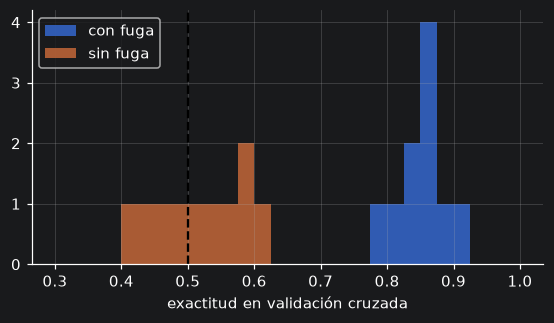

In [37]:
rng = np.random.default_rng(0)
con_fuga, sin_fuga = [], []
for rep in range(10):
    Xr = rng.normal(size=(100, 2000))
    yr = rng.integers(0, 2, 100)

    # CON FUGA: la selección ya "vio" todas las etiquetas
    Xsel = SelectKBest(f_classif, k=20).fit_transform(Xr, yr)
    con_fuga.append(cross_val_score(LogisticRegression(max_iter=500), Xsel, yr, cv=5).mean())

    pipe_ok = Pipeline([("seleccion", SelectKBest(f_classif, k=20)), ("logistica", LogisticRegression(max_iter=500))])      # ✏️ Pipeline: selección SelectKBest(f_classif, k=20) y luego LogisticRegression
    sin_fuga.append(cross_val_score(pipe_ok, Xr, yr, cv=5).mean())

print(f"Con fuga:  exactitud media = {np.mean(con_fuga):.2f}")
print(f"Sin fuga:  exactitud media = {np.mean(sin_fuga):.2f}   (azar = 0.50)")
plt.figure(figsize=(6, 3))
plt.hist(con_fuga, bins=np.linspace(0.3, 1, 29), alpha=0.8, label="con fuga")
plt.hist(sin_fuga, bins=np.linspace(0.3, 1, 29), alpha=0.8, label="sin fuga")
plt.axvline(0.5, color="k", ls="--"); plt.xlabel("exactitud en validación cruzada"); plt.legend(); plt.show()

✏️ **Pregunta 6.1.** (a) ¿Por qué el procedimiento con fuga «encuentra» un patrón que no existe? (b) En la Parte 5, escalar antes de dividir
sí es una fuga, pero casi no cambiaría los resultados; aquí la selección sí los cambia enormemente. ¿Por qué la diferencia?
(c) Nombra otra fuga posible en un problema de crédito (pista: la tabla D5 de la presentación).

**Respuesta:**

> a) Con 2 000 atributos de puro ruido y solo 100 filas, por azar algunos atributos quedan correlacionados con la etiqueta en esa muestra concreta. SelectKBest usó todas las filas (incluidas las que luego serán validación) para elegir los 20 atributos más correlacionados con y, así que ya “vio” las etiquetas de validación y eligió justo los que coinciden con ellas por casualidad. Al validar después, el modelo parece acertar (exactitud ≈ [X]), pero solo está memorizando coincidencias del azar. Sin fuga, la selección se hace dentro de cada partición con el Pipeline, los atributos elegidos no sirven para las filas nuevas y la exactitud cae al azar (≈ [Y] ≈ 0.50), que es lo correcto.

> b) Escalar antes de dividir solo filtra la media y la desviación de cada columna, que no usan la etiqueta y cambian muy poco entre el total y el entrenamiento cuando hay muchas filas; el modelo apenas gana información. La selección de atributos, en cambio, usa directamente la etiqueta para decidir qué columnas conservar, y además elige entre 2 000 candidatos, así que puede explotar muchas coincidencias del azar. La gravedad de una fuga depende de cuánta información de y del conjunto de validación se filtra.

> c) En un problema de crédito, usar una variable que solo se conoce después de otorgar el préstamo, como “número de pagos atrasados”, “enviado a cobranza” o “monto recuperado”. Están muy relacionadas con el incumplimiento (la etiqueta) porque son su consecuencia, así que el modelo parece excelente en validación, pero al momento de decidir el crédito esa información todavía no existe.

## Parte 7 — El pipeline completo *(presentación E1–E5)*

Empaquetamos imputación, escalado y codificación en un solo objeto. Después lo validamos con validación cruzada
y buscamos hiperparámetros del modelo **y** del preprocesamiento.

> Tus cifras serán parecidas, no idénticas, a las del código de la diapositiva E4: allí la división de datos no estaba estratificada.

In [38]:
num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler())])    # ✏️ Pipeline: SimpleImputer (mediana) → StandardScaler
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore"))])    # ✏️ Pipeline: SimpleImputer (most_frequent) → OneHotEncoder(handle_unknown="ignore")
prep = ColumnTransformer([("num", num_pipe, NUM),
                          ("cat", cat_pipe, CAT)])        # ✏️ ColumnTransformer con ("num", num_pipe, NUM) y ("cat", cat_pipe, CAT)

modelo = Pipeline([("prep", prep), ("knn", KNeighborsRegressor(n_neighbors=10))])

# ¿Cuántas columnas produce el preprocesador? (debería ser 13: 8 numéricas + 5 one-hot)
print("Columnas tras preprocesar:", modelo[:-1].fit(X_train, y_train).transform(X_train).shape[1])
print(list(prep.get_feature_names_out()))

m, s = cv_rmse(modelo, X_train, y_train)
print(f"\nRMSE de validación cruzada: {m:.2f} ± {s:.2f}  (miles de USD)")

Columnas tras preprocesar: 13
['num__longitude', 'num__latitude', 'num__housing_median_age', 'num__total_rooms', 'num__total_bedrooms', 'num__population', 'num__households', 'num__median_income', 'cat__ocean_proximity_<1H OCEAN', 'cat__ocean_proximity_INLAND', 'cat__ocean_proximity_ISLAND', 'cat__ocean_proximity_NEAR BAY', 'cat__ocean_proximity_NEAR OCEAN']

RMSE de validación cruzada: 61.20 ± 0.86  (miles de USD)


In [43]:
param_grid = {
    "knn__n_neighbors": [5, 10, 20],
    "prep__num__imputer__strategy": ["mean", "median"]
    # ✏️ añade el hiperparámetro del imputador numérico: "prep__num__imputer__strategy": ["mean", "median"]
}
busqueda = GridSearchCV(modelo, param_grid, cv=cv, scoring="neg_root_mean_squared_error")
busqueda.fit(X_train, y_train)

print("Mejores parámetros:", busqueda.best_params_)
print(f"RMSE de validación (mejor combinación): {-busqueda.best_score_:.2f}")
pd.DataFrame(busqueda.cv_results_)[["params", "mean_test_score"]].assign(RMSE=lambda d: -d["mean_test_score"]).drop(columns="mean_test_score").round(2)

Mejores parámetros: {'knn__n_neighbors': 10, 'prep__num__imputer__strategy': 'median'}
RMSE de validación (mejor combinación): 61.20


,params,RMSE
0,"{'knn__n_neighbors': 5, 'prep__num__imputer__s...",62.00
1,"{'knn__n_neighbors': 5, 'prep__num__imputer__s...",61.98
2,"{'knn__n_neighbors': 10, 'prep__num__imputer__...",61.20
3,"{'knn__n_neighbors': 10, 'prep__num__imputer__...",61.20
4,"{'knn__n_neighbors': 20, 'prep__num__imputer__...",61.52
5,"{'knn__n_neighbors': 20, 'prep__num__imputer__...",61.52


In [41]:
# Ahora sí: el conjunto de prueba se usa UNA sola vez, con el mejor modelo ya elegido
final = busqueda.best_estimator_
pred = final.predict(X_test)
rmse_prueba = float(np.sqrt(mean_squared_error(y_test, pred)))
print(f"RMSE en prueba: {rmse_prueba:.2f}   R² en prueba: {r2_score(y_test, pred):.3f}")

RMSE en prueba: 58.88   R² en prueba: 0.734


✏️ **Pregunta 7.1.** (a) ¿Qué significa el nombre `prep__num__imputer__strategy`? (b) ¿Por qué la búsqueda con `GridSearchCV` sobre un `Pipeline` **no** tiene fuga?
(c) Si en vez del pipeline hubieras hecho `StandardScaler().fit_transform(X)` sobre todo el conjunto y luego `GridSearchCV`, ¿qué habría salido mal?

**Respuesta:**

> a) Es la ruta para llegar a un parámetro dentro del pipeline aninado; cada `__` baja un nivel: paso `prep` (el `ColumnTransformer`) -> tubo `num` (el pipeline numérico) -> paso `imputer` (el `SimpleImputer`) -> parámetro `strategy`. Así `GridSearchCV` puede probar `"mean"` y `"median"` en el imputador numérico, que es un hiperparámetro del preprocesamiento y no del modelo.

> b) Porque el preprocesamiento va dentro del Pipeline: en cada fold de la validación cruzada, GridSearchCV ajusta (fit) el imputador, el escalador y el one-hot solo con la parte de entrenamiento de ese fold, y luego transforma el fold de validación con esos valores. El fold de validación nunca influye en la mediana, la media, la desviación ni las categorías aprendidas, así que funciona como datos realmente nuevos.

> c) El escalador habría calculado la media y la desviación con todo el conjunto, incluidas las filas que después sirven de validación en cada fold. Esa información del fold de validación ya estaría incorporada en los datos de entrenamiento, así que el RMSE de validación saldría un poco más optimista que el real y la elección de hiperparámetros se haría con una evaluación contaminada. Como vimos en la Parte 6, con el escalado el efecto sería pequeño (no usa la etiqueta), pero sigue siendo fuga.

## Parte 8 — Tabla comparativa y resumen *(entregable)*

Compara estrategias completas de preprocesamiento con el **mismo modelo** (KNN, $k=10$) y la **misma validación cruzada**
sobre el conjunto de entrenamiento. Es el experimento de la segunda diapositiva de la presentación, ahora con tu propio código.

In [44]:
resultados, pipes = [], {}

def evalua(nombre, pipe, Xd=None, yd=None):
    Xd = X_train if Xd is None else Xd
    yd = y_train if yd is None else yd
    m, s = cv_rmse(pipe, Xd, yd)
    resultados.append({"estrategia": nombre, "RMSE validación": round(m, 2), "± desv": round(s, 2), "comentario": ""})
    pipes[nombre] = pipe
    print(f"{nombre:55s} {m:6.2f} ± {s:4.2f}")

def crea_prep(imp_num, esc):
    # preprocesador completo: numéricas (imputar + escalar) y categórica (moda + one-hot)
    return ColumnTransformer([
        ("num", make_pipeline(imp_num, esc), NUM),
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), CAT)])

knn = lambda: KNeighborsRegressor(n_neighbors=10)
completas = X_train.dropna().index

evalua("1. Borrar filas incompletas, sin escalar", Pipeline([("knn", knn())]), X_train.loc[completas, NUM], y_train.loc[completas])
evalua("2. Imputar con mediana, sin escalar", make_pipeline(SimpleImputer(strategy="median"), knn()), X_train[NUM])
evalua("3. + estandarizar", make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), knn()), X_train[NUM])
evalua("4. + one-hot de ocean_proximity",
       Pipeline([("prep", crea_prep(SimpleImputer(strategy="median"), StandardScaler())), ("knn", knn())]))
# ✏️ Completa las estrategias 5, 6 y 7 (cambia solo el argumento de crea_prep):
evalua("5. Como 4, pero con RobustScaler",
       Pipeline([("prep", crea_prep(SimpleImputer(strategy="median"), RobustScaler())), ("knn", knn())]))
evalua("6. Como 4, pero imputando con KNNImputer",
       Pipeline([("prep", crea_prep(KNNImputer(n_neighbors=10), StandardScaler())), ("knn", knn())]))
evalua("7. Como 4, con indicador de faltante",
       Pipeline([("prep", crea_prep(SimpleImputer(strategy="median", add_indicator=True), StandardScaler())), ("knn", knn())]))

1. Borrar filas incompletas, sin escalar                 96.78 ± 0.91
2. Imputar con mediana, sin escalar                      96.63 ± 0.42
3. + estandarizar                                        62.59 ± 1.44
4. + one-hot de ocean_proximity                          61.20 ± 0.86
5. Como 4, pero con RobustScaler                         61.29 ± 1.02
6. Como 4, pero imputando con KNNImputer                 61.14 ± 0.84
7. Como 4, con indicador de faltante                     61.40 ± 0.94


In [45]:
tabla_final = pd.DataFrame(resultados)
# ✏️ Escribe una frase por estrategia, p. ej.:  tabla_final.loc[0, "comentario"] = "…"
tabla_final.loc[0, "comentario"] = "Sin escalar, KNN queda dominado por variables grandes; borrar ~1% de filas apenas cambia el resultado."
tabla_final.loc[1, "comentario"] = "Igual que borrar: con solo ~1% de faltantes la imputación casi no influye, pero no se pierden filas."
tabla_final.loc[2, "comentario"] = "El cambio más grande: estandarizar hace que todas las variables cuenten en la distancia de KNN."
tabla_final.loc[3, "comentario"] = "Agregar ocean_proximity con one-hot aporta información de ubicación y mejora un poco."
tabla_final.loc[4, "comentario"] = "RobustScaler da prácticamente lo mismo; la diferencia está dentro de la variación entre folds."
tabla_final.loc[5, "comentario"] = "El mejor RMSE, pero la mejora sobre la mediana es mínima porque faltan muy pocos valores."
tabla_final.loc[6, "comentario"] = "El indicador no ayuda: los faltantes parecen MCAR, así que 'faltar' no da información del precio."
tabla_final

,estrategia,RMSE validación,± desv,comentario
0,"1. Borrar filas incompletas, sin escalar",96.78,0.91,"Sin escalar, KNN queda dominado por variables ..."
1,"2. Imputar con mediana, sin escalar",96.63,0.42,Igual que borrar: con solo ~1% de faltantes la...
2,3. + estandarizar,62.59,1.44,El cambio más grande: estandarizar hace que to...
3,4. + one-hot de ocean_proximity,61.20,0.86,Agregar ocean_proximity con one-hot aporta inf...
4,"5. Como 4, pero con RobustScaler",61.29,1.02,RobustScaler da prácticamente lo mismo; la dif...
5,"6. Como 4, pero imputando con KNNImputer",61.14,0.84,"El mejor RMSE, pero la mejora sobre la mediana..."
6,"7. Como 4, con indicador de faltante",61.40,0.94,El indicador no ayuda: los faltantes parecen M...


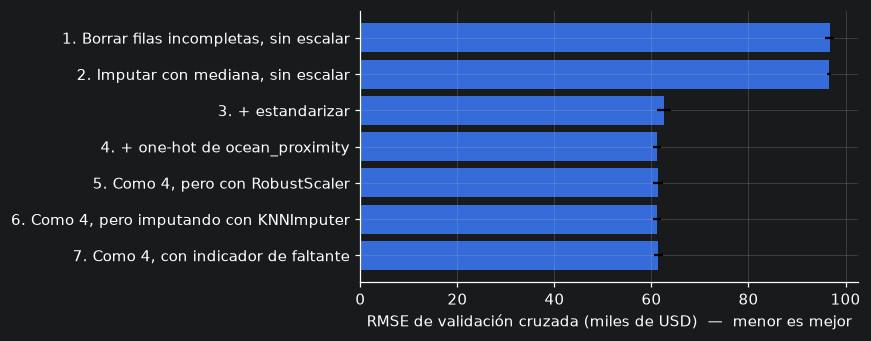

Guardado: entregable_unidad2.csv


In [46]:
plt.figure(figsize=(8, 3.2))
plt.barh(tabla_final["estrategia"][::-1], tabla_final["RMSE validación"][::-1], xerr=tabla_final["± desv"][::-1], color="C0")
plt.xlabel("RMSE de validación cruzada (miles de USD)  —  menor es mejor"); plt.tight_layout(); plt.show()

# Guarda la tabla para entregarla junto con el notebook
tabla_final.to_csv("entregable_unidad2.csv", index=False, encoding="utf-8")
print("Guardado: entregable_unidad2.csv")

In [51]:
# Mejor estrategia por validación → ajuste con TODO el entrenamiento → UNA evaluación en prueba
mejor = "6. Como 4, pero imputando con KNNImputer"        # ✏️ nombre de la estrategia 4–7 con menor RMSE de validación (cópialo de la tabla)
pipe_mejor = pipes[mejor]
pipe_mejor.fit(X_train, y_train)
pred = pipe_mejor.predict(X_test)
print(mejor)
print(f"RMSE en prueba: {np.sqrt(mean_squared_error(y_test, pred)):.2f}   R² en prueba: {r2_score(y_test, pred):.3f}")

6. Como 4, pero imputando con KNNImputer
RMSE en prueba: 58.86   R² en prueba: 0.734


### Reflexión final (3–5 líneas)

1. De todas las decisiones de preprocesamiento que probaste, ¿cuál cambió **más** el error y cuál casi nada? Relaciónalo con lo que pasa con los datos (escala, faltantes, categoría).
2. ¿Qué parte de este flujo habría tenido fuga si no hubieras usado `Pipeline`? ¿Y si hubieras escogido hiperparámetros mirando el conjunto de prueba?
3. Escribe tu **receta personal** (3 pasos) para empezar cualquier problema con datos tabulares nuevos.

**Respuesta:**

> 1. Lo que más cambió el error fue estandarizar: el RMSE bajó de 96.6 a 62.6, porque KNN usa distancias y sin escalar las variables con valores grandes (`population`, `total_rooms`) dominaban. Lo que casi no cambió fue cómo tratar los faltantes: borrar filas, imputar con mediana, con KNNImputer o agregar el indicador dio prácticamente lo mismo, porque solo falta ~1 % de `total_bedrooms` y los faltantes parecen MCAR. La categoría (one-hot) mejoró un poco (62.6 → 61.2) al aportar información de ubicación.
> 2. Sin `Pipeline`, habría fuga en todos los pasos que aprenden de los datos: la mediana del imputador (o los vecinos del KNNImputer), la media y desviación del escalador y las categorías del one-hot se habrían calculado con todo `X_train`, incluidas las filas que luego sirven de validación en cada fold. Así, la validación cruzada ya no evaluaría con datos realmente nuevos y el RMSE saldría optimista. Si hubiera escogido los hiperparámetros mirando el conjunto de prueba, el test dejaría de ser “datos nuevos”: lo estaría usando para tomar decisiones, igual que la validación. Al probar varias opciones y quedarme con la que mejor le va al test, elijo en parte la que mejor se ajusta por azar a esas filas concretas, así que el RMSE de prueba saldría optimista y ya no tendría una estimación honesta del error con datos realmente nuevos. Por eso los hiperparámetros se eligen con validación cruzada sobre el entrenamiento (`GridSearchCV`) y el test se usa una sola vez, al final.
> 3. Mi receta:
>
>    1\. Explorar y dividir primero: revisar tipos de variables, faltantes (cuántos y si parecen MCAR/MAR/MNAR), faltantes disfrazados y valores atípicos; luego separar un 20 % de prueba, estratificando por la variable más relacionada con el objetivo, y no volver a tocarlo.
>
>    2\. Preprocesar dentro de un Pipeline: imputar, escalar (si el modelo usa distancias o gradientes) y codificar categorías con one-hot, todo en un ColumnTransformer, para que cada paso se ajuste solo con el entrenamiento de cada fold.
>
>    3\. Comparar con validación cruzada y probar una sola vez: comparar modelos y estrategias de preprocesamiento con CV o GridSearchCV sobre el entrenamiento, elegir la mejor y evaluarla una única vez en el conjunto de prueba.

---
### Reto opcional

Reemplaza `KNeighborsRegressor` por `DecisionTreeRegressor(max_depth=8)` en la estrategia 4 y compara contra las estrategias 2 y 3 (¿le importa el escalado?);
luego prueba `OneHotEncoder(handle_unknown="ignore", min_frequency=100)` y explica qué hace con `ISLAND`.

In [52]:
# Reto opcional
arbol = lambda: DecisionTreeRegressor(max_depth=8, random_state=0)
for nombre, pipe, Xd in [
    ("árbol, mediana, sin escalar", make_pipeline(SimpleImputer(strategy="median"), arbol()), X_train[NUM]),
    ("árbol, mediana + estandarizar", make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), arbol()), X_train[NUM]),
    ("árbol, preprocesador completo", Pipeline([("prep", crea_prep(SimpleImputer(strategy="median"), StandardScaler())), ("arbol", arbol())]), X_train),
]:
    m, s = cv_rmse(pipe, Xd, y_train)
    print(f"{nombre:34s} {m:6.2f} ± {s:4.2f}")

oh_raros = OneHotEncoder(handle_unknown="ignore", min_frequency=100).fit(X_train[CAT])
print("\nCategorías tras min_frequency=100:", list(oh_raros.get_feature_names_out()))

árbol, mediana, sin escalar         66.86 ± 2.29
árbol, mediana + estandarizar       66.87 ± 2.25
árbol, preprocesador completo       64.01 ± 1.60

Categorías tras min_frequency=100: ['ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN', 'ocean_proximity_infrequent_sklearn']
